# WFP2 – Pilotexperiment: Remissionsvorhersage mit Logistic Regression

In diesem Notebook wird ein erstes Klassifikationsmodell zur Vorhersage der Remission nach 12 Monaten erstellt.

Ziel ist es zu vergleichen, ob frühe longitudinale klinische Informationen einen zusätzlichen Vorhersagewert gegenüber reinen Baseline-Daten liefern.

Verglichen werden:

- **Baseline-Modell:** ausschließlich klinische Merkmale zum Ausgangszeitpunkt
- **Longitudinales Modell:** Baseline-Merkmale plus frühe Verlaufsinformationen

Die Zielvariable ist die Remission nach 12 Monaten:

- DAS28 < 2.6 → Remission
- DAS28 ≥ 2.6 → keine Remission

Als Modell wird zunächst eine **Logistic Regression** verwendet.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../../datasets_final/Clinical_Clean_Merged.csv")

print("Shape:", df.shape)
df.head()

Shape: (275, 73)


,Patient_ID,Digest,ACPA.POSITIVE,RHUEMATOID.FACTOR,DAS28.0M,DAS28.3M,DAS28.6M,DAS28.9M,DAS28.12M,DAS28.18M,...,intraarticular_count,intramuscular_count,first_injection,last_injection,med_event_count,unique_medications,total_dose_y,mean_dose_y,first_med_date,last_med_date
0,TAC1000,B1895B6B8F7B325B977C180A25C74D079EFB5EB306693D...,1.0,1.0,7.27,1.91,2.13,1.14,1.54,1.13,...,NaN,NaN,NaN,NaN,18.0,3.0,1350.0,75.000000,2013-03-18,2013-05-02
1,TAC1001,59749E6B6785A9983100DA76AB0AE9484B52B2422AB362...,1.0,1.0,7.83,5.37,3.59,2.73,2.56,2.68,...,1.0,2.0,2013-02-05 00:00:00.000000000,2013-06-02 00:00:00.000000000,21.0,4.0,1480.0,70.476190,2013-02-05,2014-09-05
2,TAC1002,9C459B98832CB4E81C90B843BF7A7925D5E01A1A306586...,1.0,1.0,3.43,0.77,0.49,0.97,2.34,0.51,...,1.0,1.0,2013-08-05 00:00:00.000000000,2013-08-05 00:00:00.000000000,12.0,2.0,7200.0,600.000000,2013-05-29,2013-08-05
3,TAC1003,308098EB685FC45FA0CA61C88D25D810E16C9DADBBA77C...,1.0,1.0,5.76,3.59,2.91,2.88,2.01,2.62,...,0.0,1.0,2013-07-06 00:00:00.000000000,2013-07-06 00:00:00.000000000,18.0,3.0,2350.0,130.555556,2013-04-12,2014-12-05
4,TAC1004,3A9C04CAA9BBAAE16A20614D827FA3B55AA09C94F69284...,1.0,1.0,6.52,2.13,1.47,1.75,3.27,2.02,...,NaN,NaN,NaN,NaN,15.0,3.0,1122.5,74.833333,2013-09-13,2014-08-08


In [3]:
# Zielvariable für das Pilotexperiment erstellen:
# Wenn DAS28 nach 12 Monaten kleiner als 2.6 ist,
# gilt die Person als in Remission.
# True wird durch astype(int) zu 1, False zu 0.
df["remission_12m"] = (df["DAS28.12M"] < 2.6).astype(int)


# Baseline-Features:
# Diese Merkmale stehen bereits zum Ausgangszeitpunkt zur Verfügung.
# Sie bilden die Eingabe für das reine Baseline-Modell.
baseline_features = [
    "DAS28.0M",
    "CRP.0M",
    "ESR.0M",
    "HAQ.0M",
    "AGE",
    "GENDER",
    "RHUEMATOID.FACTOR",
    "ACPA.POSITIVE"
]


# Longitudinale Features:
# Zuerst werden alle Baseline-Features übernommen.
# Zusätzlich kommen frühe Verlaufswerte aus 3 bzw. 6 Monaten dazu.
# Damit soll später geprüft werden, ob Verlaufsinformationen
# die Vorhersage der Remission nach 12 Monaten verbessern.
longitudinal_features = baseline_features + [
    "DAS28.3M",
    "DAS28.6M",
    "CRP.6M",
    "HAQ.6M"
]


# Anzahl der ausgewählten Features zur Kontrolle ausgeben
print("Baseline-Features:", len(baseline_features))
print("Longitudinale Features:", len(longitudinal_features))


# Verteilung der Zielvariable ausgeben:
# 0 = keine Remission
# 1 = Remission
print("\nTarget-Verteilung:")
print(df["remission_12m"].value_counts())

Baseline-Features: 8
Longitudinale Features: 12

Target-Verteilung:
remission_12m
0    204
1     71
Name: count, dtype: int64


In [4]:
# Eingabedaten für das Baseline-Modell
X_baseline = df[baseline_features]

# Eingabedaten für das longitudinale Modell
X_longitudinal = df[longitudinal_features]

# Zielvariable (Ist die Person nach 12 Monaten in Remission oder nicht?)
# df["remission_12m"] = (df["DAS28.12M"] < 2.6).astype(int)
# 1 = Remission nach 12 Monaten
# 0 = keine Remission nach 12 Monaten
y = df["remission_12m"]


# Kontrolle der Dimensionen
print("X_baseline:", X_baseline.shape)
print("X_longitudinal:", X_longitudinal.shape)
print("y:", y.shape)

X_baseline: (275, 8)
X_longitudinal: (275, 12)
y: (275,)


In [5]:
# Binäre Merkmale:
# Diese Merkmale sind im Datensatz als 0/1 codiert.
# Bei diesen Variablen gibt es außerdem einige fehlende Werte.
binary_features = [
    "GENDER",
    "RHUEMATOID.FACTOR",
    "ACPA.POSITIVE"
]


# Numerische Baseline-Features:
# Kontinuierliche klinische Werte, die zum Ausgangszeitpunkt verfügbar sind.
numeric_baseline_features = [
    "DAS28.0M",
    "CRP.0M",
    "ESR.0M",
    "HAQ.0M",
    "AGE"
]


# Numerische longitudinale Features:
# Zusätzlich zu den numerischen Baseline-Werten
# werden frühe Verlaufswerte aus 3 bzw. 6 Monaten verwendet.
numeric_longitudinal_features = numeric_baseline_features + [
    "DAS28.3M",
    "DAS28.6M",
    "CRP.6M",
    "HAQ.6M"
]


# Kontrolle der Anzahl der Features
print("Numerische Baseline-Features:", len(numeric_baseline_features))
print("Numerische longitudinale Features:", len(numeric_longitudinal_features))
print("Binäre Features:", len(binary_features))

Numerische Baseline-Features: 5
Numerische longitudinale Features: 9
Binäre Features: 3


In [6]:
# Werkzeuge für die Vorverarbeitung importieren
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# Vorverarbeitung für numerische Features:
# Falls ein numerischer Wert fehlt, wird er durch den Median ersetzt.
# Danach werden die numerischen Werte standardisiert.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Vorverarbeitung für binäre Features:
# Fehlende Werte werden durch den am häufigsten vorkommenden Wert ersetzt.
# Eine Skalierung ist hier nicht notwendig, da die Werte bereits als 0/1 codiert sind.
binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])


# Vorverarbeitung für das Baseline-Modell:
# Die numerischen und binären Features werden getrennt behandelt.
baseline_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_baseline_features),
        ("binary", binary_transformer, binary_features)
    ]
)


# Vorverarbeitung für das longitudinale Modell:
# Hier werden zusätzlich die frühen longitudinalen numerischen Werte berücksichtigt.
longitudinal_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_longitudinal_features),
        ("binary", binary_transformer, binary_features)
    ]
)


print("Preprocessing für Baseline- und longitudinales Modell wurde erstellt.")

Preprocessing für Baseline- und longitudinales Modell wurde erstellt.


In [7]:
# Logistic Regression importieren
from sklearn.linear_model import LogisticRegression


# Logistic Regression für das Baseline-Modell erstellen
# max_iter wird erhöht, damit das Modell genügend Iterationen
# für die Optimierung zur Verfügung hat.
baseline_model = Pipeline(steps=[
    ("preprocessor", baseline_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])


# Logistic Regression für das longitudinale Modell erstellen
# Der einzige Unterschied ist die verwendete Vorverarbeitung,
# da hier zusätzliche Verlaufswerte berücksichtigt werden.
longitudinal_model = Pipeline(steps=[
    ("preprocessor", longitudinal_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])


print("Baseline- und longitudinales Logistic-Regression-Modell wurden erstellt.")

Baseline- und longitudinales Logistic-Regression-Modell wurden erstellt.


In [8]:
# Werkzeuge für die Cross-Validation importieren
from sklearn.model_selection import StratifiedKFold, cross_validate


# Stratified 5-Fold Cross-Validation erstellen:
# Die 275 Patient:innen werden in 5 Teile aufgeteilt.
# Dabei bleibt das Verhältnis von Remission / keine Remission
# in jedem Fold ungefähr gleich.
#
# shuffle=True mischt die Patient:innen vor der Aufteilung.
# random_state=42 sorgt dafür, dass die Aufteilung reproduzierbar bleibt.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Metriken festlegen, mit denen die Modelle später bewertet werden.
# Wegen der ungleichen Klassenverteilung verwenden wir nicht nur Accuracy.
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


print("Stratified 5-Fold Cross-Validation und Bewertungsmetriken wurden erstellt.")

Stratified 5-Fold Cross-Validation und Bewertungsmetriken wurden erstellt.


In [9]:
# Baseline-Modell mit Stratified 5-Fold Cross-Validation auswerten
# Das Modell wird dabei 5-mal neu trainiert.
# Bei jedem Durchlauf werden 4 Folds zum Trainieren
# und 1 Fold zum Testen verwendet.
baseline_scores = cross_validate(
    baseline_model,
    X_baseline,
    y,
    cv=cv,
    scoring=scoring
)


# Longitudinales Modell mit derselben Cross-Validation auswerten
# Dadurch können beide Modelle fair miteinander verglichen werden.
longitudinal_scores = cross_validate(
    longitudinal_model,
    X_longitudinal,
    y,
    cv=cv,
    scoring=scoring
)


print("Cross-Validation für beide Modelle abgeschlossen.")

Cross-Validation für beide Modelle abgeschlossen.


In [10]:
# Ergebnisse der Cross-Validation zusammenfassen.
# Für jede Metrik wird der Mittelwert über alle 5 Folds berechnet.
# Zusätzlich wird die Standardabweichung ausgegeben.
# Dadurch sehen wir nicht nur die durchschnittliche Leistung,
# sondern auch, wie stark die Ergebnisse zwischen den Folds schwanken.

results = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Baseline Mittelwert": [
        baseline_scores["test_accuracy"].mean(),
        baseline_scores["test_balanced_accuracy"].mean(),
        baseline_scores["test_precision"].mean(),
        baseline_scores["test_recall"].mean(),
        baseline_scores["test_f1"].mean(),
        baseline_scores["test_roc_auc"].mean()
    ],

    "Baseline Std": [
        baseline_scores["test_accuracy"].std(),
        baseline_scores["test_balanced_accuracy"].std(),
        baseline_scores["test_precision"].std(),
        baseline_scores["test_recall"].std(),
        baseline_scores["test_f1"].std(),
        baseline_scores["test_roc_auc"].std()
    ],

    "Longitudinal Mittelwert": [
        longitudinal_scores["test_accuracy"].mean(),
        longitudinal_scores["test_balanced_accuracy"].mean(),
        longitudinal_scores["test_precision"].mean(),
        longitudinal_scores["test_recall"].mean(),
        longitudinal_scores["test_f1"].mean(),
        longitudinal_scores["test_roc_auc"].mean()
    ],

    "Longitudinal Std": [
        longitudinal_scores["test_accuracy"].std(),
        longitudinal_scores["test_balanced_accuracy"].std(),
        longitudinal_scores["test_precision"].std(),
        longitudinal_scores["test_recall"].std(),
        longitudinal_scores["test_f1"].std(),
        longitudinal_scores["test_roc_auc"].std()
    ]
})


# Werte auf drei Nachkommastellen runden
results = results.round(3)

results

,Metrik,Baseline Mittelwert,Baseline Std,Longitudinal Mittelwert,Longitudinal Std
0,Accuracy,0.74500,0.04100,0.72000,0.04400
1,Balanced Accuracy,0.53500,0.05000,0.51800,0.03500
2,Precision,0.70000,0.40000,0.39400,0.34200
3,Recall,0.09900,0.07300,0.09900,0.05800
4,F1,0.16700,0.11700,0.15000,0.09000
5,ROC-AUC,0.60900,0.07800,0.63400,0.08500


In [11]:
# Werkzeug für Cross-Validation-Vorhersagen importieren
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix


# Vorhersagen für das Baseline-Modell erzeugen.
# Jede Person wird genau in dem Fold vorhergesagt,
# in dem sie als Testperson verwendet wird.
baseline_predictions = cross_val_predict(
    baseline_model,
    X_baseline,
    y,
    cv=cv,
    method="predict"
)


# Vorhersagen für das longitudinale Modell erzeugen.
# Auch hier wird jede Person nur von einem Modell vorhergesagt,
# das diese Person beim Training nicht gesehen hat.
longitudinal_predictions = cross_val_predict(
    longitudinal_model,
    X_longitudinal,
    y,
    cv=cv,
    method="predict"
)


# Confusion Matrices berechnen
baseline_cm = confusion_matrix(y, baseline_predictions)
longitudinal_cm = confusion_matrix(y, longitudinal_predictions)


print("Confusion Matrix - Baseline:")
print(baseline_cm)

print("\nConfusion Matrix - Longitudinal:")
print(longitudinal_cm)

Confusion Matrix - Baseline:
[[198   6]
 [ 64   7]]

Confusion Matrix - Longitudinal:
[[191  13]
 [ 64   7]]


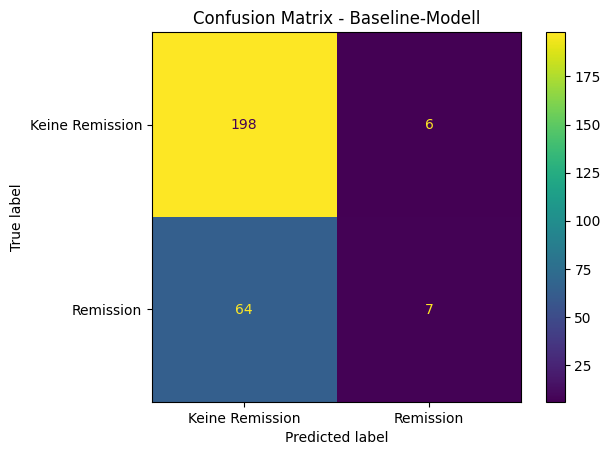

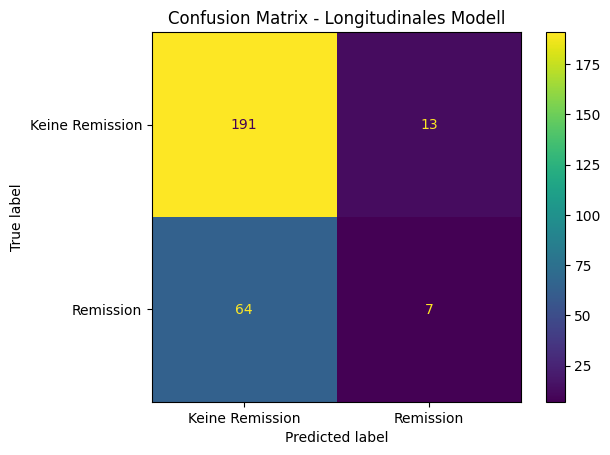

In [12]:
# Confusion Matrices grafisch darstellen
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# Baseline-Modell
ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=["Keine Remission", "Remission"]
).plot()

plt.title("Confusion Matrix - Baseline-Modell")
plt.show()


# Longitudinales Modell
ConfusionMatrixDisplay(
    confusion_matrix=longitudinal_cm,
    display_labels=["Keine Remission", "Remission"]
).plot()

plt.title("Confusion Matrix - Longitudinales Modell")
plt.show()

In [13]:
# Neue Logistic-Regression-Modelle mit class_weight="balanced"
# Dadurch bekommt die kleinere Klasse "Remission" beim Training mehr Gewicht.

baseline_model_balanced = Pipeline(steps=[
    ("preprocessor", baseline_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])


longitudinal_model_balanced = Pipeline(steps=[
    ("preprocessor", longitudinal_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])


print("Balanced Logistic-Regression-Modelle wurden erstellt.")

Balanced Logistic-Regression-Modelle wurden erstellt.


In [14]:
# Balanced Baseline-Modell mit derselben
# Stratified 5-Fold Cross-Validation auswerten.
baseline_balanced_scores = cross_validate(
    baseline_model_balanced,
    X_baseline,
    y,
    cv=cv,
    scoring=scoring
)


# Balanced longitudinales Modell mit derselben
# Stratified 5-Fold Cross-Validation auswerten.
longitudinal_balanced_scores = cross_validate(
    longitudinal_model_balanced,
    X_longitudinal,
    y,
    cv=cv,
    scoring=scoring
)


print("Cross-Validation für beide Balanced-Modelle abgeschlossen.")

Cross-Validation für beide Balanced-Modelle abgeschlossen.


In [15]:
# Vergleich der normalen und der Balanced-Modelle.
# Für jede Metrik wird wieder der Mittelwert über die 5 Folds berechnet.

comparison_balanced = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Baseline Normal": [
        baseline_scores["test_accuracy"].mean(),
        baseline_scores["test_balanced_accuracy"].mean(),
        baseline_scores["test_precision"].mean(),
        baseline_scores["test_recall"].mean(),
        baseline_scores["test_f1"].mean(),
        baseline_scores["test_roc_auc"].mean()
    ],

    "Baseline Balanced": [
        baseline_balanced_scores["test_accuracy"].mean(),
        baseline_balanced_scores["test_balanced_accuracy"].mean(),
        baseline_balanced_scores["test_precision"].mean(),
        baseline_balanced_scores["test_recall"].mean(),
        baseline_balanced_scores["test_f1"].mean(),
        baseline_balanced_scores["test_roc_auc"].mean()
    ],

    "Longitudinal Normal": [
        longitudinal_scores["test_accuracy"].mean(),
        longitudinal_scores["test_balanced_accuracy"].mean(),
        longitudinal_scores["test_precision"].mean(),
        longitudinal_scores["test_recall"].mean(),
        longitudinal_scores["test_f1"].mean(),
        longitudinal_scores["test_roc_auc"].mean()
    ],

    "Longitudinal Balanced": [
        longitudinal_balanced_scores["test_accuracy"].mean(),
        longitudinal_balanced_scores["test_balanced_accuracy"].mean(),
        longitudinal_balanced_scores["test_precision"].mean(),
        longitudinal_balanced_scores["test_recall"].mean(),
        longitudinal_balanced_scores["test_f1"].mean(),
        longitudinal_balanced_scores["test_roc_auc"].mean()
    ]
})


# Werte auf drei Nachkommastellen runden
comparison_balanced = comparison_balanced.round(3)

comparison_balanced

,Metrik,Baseline Normal,Baseline Balanced,Longitudinal Normal,Longitudinal Balanced
0,Accuracy,0.74500,0.56700,0.72000,0.62200
1,Balanced Accuracy,0.53500,0.57100,0.51800,0.61600
2,Precision,0.70000,0.32500,0.39400,0.36800
3,Recall,0.09900,0.57800,0.09900,0.60500
4,F1,0.16700,0.41200,0.15000,0.45400
5,ROC-AUC,0.60900,0.61100,0.63400,0.63200


In [16]:
# Vorhersagen für das Balanced Baseline-Modell erzeugen.
# Jede Person wird wieder nur von einem Modell vorhergesagt,
# das diese Person beim Training nicht gesehen hat.
baseline_balanced_predictions = cross_val_predict(
    baseline_model_balanced,
    X_baseline,
    y,
    cv=cv,
    method="predict"
)


# Vorhersagen für das Balanced longitudinale Modell erzeugen.
longitudinal_balanced_predictions = cross_val_predict(
    longitudinal_model_balanced,
    X_longitudinal,
    y,
    cv=cv,
    method="predict"
)


# Confusion Matrices für die Balanced-Modelle berechnen.
baseline_balanced_cm = confusion_matrix(
    y,
    baseline_balanced_predictions
)

longitudinal_balanced_cm = confusion_matrix(
    y,
    longitudinal_balanced_predictions
)


print("Confusion Matrix - Baseline Balanced:")
print(baseline_balanced_cm)

print("\nConfusion Matrix - Longitudinal Balanced:")
print(longitudinal_balanced_cm)

Confusion Matrix - Baseline Balanced:
[[115  89]
 [ 30  41]]

Confusion Matrix - Longitudinal Balanced:
[[128  76]
 [ 28  43]]


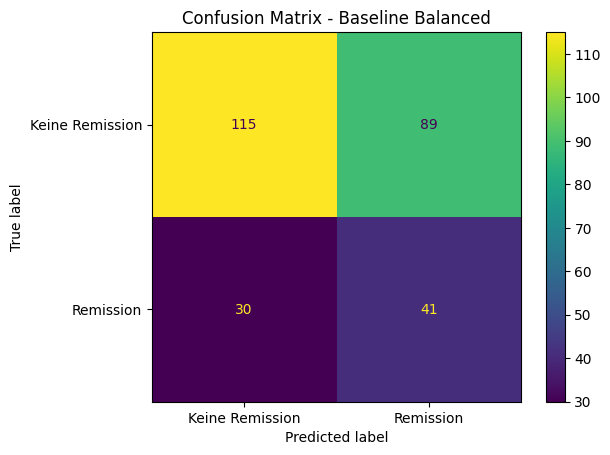

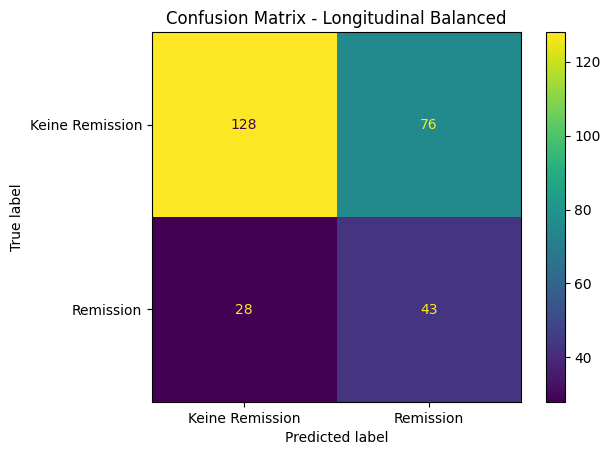

In [17]:
# Confusion Matrix des Balanced Baseline-Modells darstellen
ConfusionMatrixDisplay(
    confusion_matrix=baseline_balanced_cm,
    display_labels=["Keine Remission", "Remission"]
).plot()

plt.title("Confusion Matrix - Baseline Balanced")
plt.show()


# Confusion Matrix des Balanced longitudinalen Modells darstellen
ConfusionMatrixDisplay(
    confusion_matrix=longitudinal_balanced_cm,
    display_labels=["Keine Remission", "Remission"]
).plot()

plt.title("Confusion Matrix - Longitudinal Balanced")
plt.show()

In [18]:
# Wahrscheinlichkeiten für die Remissionsklasse berechnen.
# predict_proba liefert für jede Person die Wahrscheinlichkeit
# für Klasse 0 und Klasse 1.
#
# [:, 1] bedeutet:
# Wir verwenden nur die Wahrscheinlichkeit für Klasse 1 = Remission.

baseline_probabilities = cross_val_predict(
    baseline_model_balanced,
    X_baseline,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]


longitudinal_probabilities = cross_val_predict(
    longitudinal_model_balanced,
    X_longitudinal,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]


print("Wahrscheinlichkeiten für beide Balanced-Modelle wurden berechnet.")

Wahrscheinlichkeiten für beide Balanced-Modelle wurden berechnet.


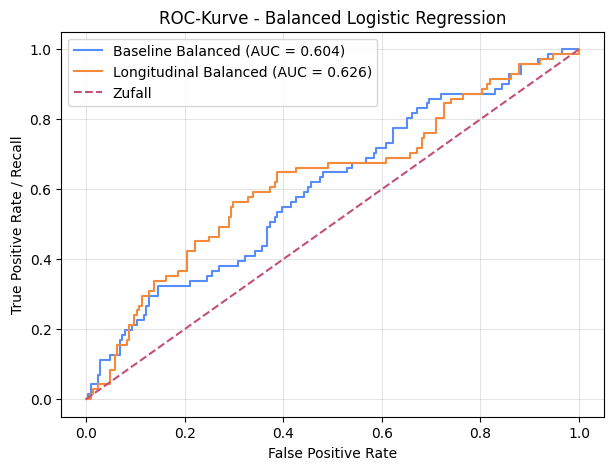

Baseline Balanced ROC-AUC: 0.604
Longitudinal Balanced ROC-AUC: 0.626


In [19]:
# Werkzeuge für ROC-Kurve und ROC-AUC importieren
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


# ROC-Kurve für das Balanced Baseline-Modell berechnen.
# fpr = False Positive Rate
# tpr = True Positive Rate bzw. Recall
baseline_fpr, baseline_tpr, _ = roc_curve(
    y,
    baseline_probabilities
)

# ROC-AUC für das Baseline-Modell berechnen
baseline_auc = roc_auc_score(
    y,
    baseline_probabilities
)


# ROC-Kurve für das Balanced longitudinale Modell berechnen
longitudinal_fpr, longitudinal_tpr, _ = roc_curve(
    y,
    longitudinal_probabilities
)

# ROC-AUC für das longitudinale Modell berechnen
longitudinal_auc = roc_auc_score(
    y,
    longitudinal_probabilities
)


# Beide ROC-Kurven in einer Grafik darstellen
plt.figure(figsize=(7, 5))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f"Baseline Balanced (AUC = {baseline_auc:.3f})"
)

plt.plot(
    longitudinal_fpr,
    longitudinal_tpr,
    label=f"Longitudinal Balanced (AUC = {longitudinal_auc:.3f})"
)


# Diagonale Referenzlinie:
# Ein Modell auf dieser Linie würde ungefähr zufällig klassifizieren.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Zufall"
)


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC-Kurve - Balanced Logistic Regression")
plt.legend()
plt.grid()

plt.show()


# ROC-AUC zusätzlich als Zahlen ausgeben
print("Baseline Balanced ROC-AUC:", round(baseline_auc, 3))
print("Longitudinal Balanced ROC-AUC:", round(longitudinal_auc, 3))

### Zwischenfazit

Das longitudinale Balanced-Modell erreicht mit einer ROC-AUC von 0.626 eine leicht höhere Trennleistung als das Baseline Balanced-Modell mit 0.604.

Die longitudinale Erweiterung zeigt damit einen kleinen Vorteil gegenüber der ausschließlichen Verwendung von Baseline-Daten. Insgesamt ist die Trennleistung der beiden Modelle jedoch noch begrenzt.

In [20]:
# Das longitudinale Balanced-Modell einmal auf allen Daten trainieren.
# Dieses Training dient nur dazu, die gelernten Koeffizienten
# der Logistic Regression untersuchen zu können.
#
# Für die Bewertung des Modells verwenden wir weiterhin
# die Ergebnisse der 5-Fold Cross-Validation.

longitudinal_model_balanced.fit(
    X_longitudinal,
    y
)


# Namen der Features nach dem Preprocessing auslesen
feature_names = longitudinal_model_balanced[
    "preprocessor"
].get_feature_names_out()


# Gelernte Koeffizienten der Logistic Regression auslesen
coefficients = longitudinal_model_balanced[
    "classifier"
].coef_[0]


# Feature-Namen und Koeffizienten in einer Tabelle zusammenfassen
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Koeffizient": coefficients
})


# Nach der Stärke des Koeffizienten sortieren
coefficient_table["Absoluter Koeffizient"] = (
    coefficient_table["Koeffizient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absoluter Koeffizient",
    ascending=False
)


coefficient_table.round(3)

,Feature,Koeffizient,Absoluter Koeffizient
6,numeric__DAS28.6M,-0.56600,0.56600
2,numeric__ESR.0M,-0.46900,0.46900
9,binary__GENDER,0.46300,0.46300
4,numeric__AGE,-0.22400,0.22400
7,numeric__CRP.6M,0.12100,0.12100
10,binary__RHUEMATOID.FACTOR,0.08600,0.08600
1,numeric__CRP.0M,0.07200,0.07200
5,numeric__DAS28.3M,-0.06200,0.06200
3,numeric__HAQ.0M,0.06000,0.06000
0,numeric__DAS28.0M,0.05900,0.05900


### Interpretation der Modellkoeffizienten

Im longitudinalen Balanced-Modell zeigt DAS28 nach 6 Monaten den stärksten negativen Koeffizienten. Ein höherer DAS28-Wert nach 6 Monaten ist damit im Modell mit einer geringeren Wahrscheinlichkeit für Remission nach 12 Monaten verbunden.

Auch ESR zu Baseline und höheres Alter zeigen negative Koeffizienten. Das Geschlechtsmerkmal weist einen vergleichsweise starken positiven Koeffizienten auf, wobei die genaue Bedeutung der 0/1-Codierung noch verifiziert werden muss.

Die Koeffizienten beschreiben Zusammenhänge innerhalb des Modells und dürfen nicht als kausale Effekte interpretiert werden.

In [21]:
# GridSearchCV für das Hyperparameter-Tuning importieren
from sklearn.model_selection import GridSearchCV


# Verschiedene Werte für den Hyperparameter C testen.
# C beeinflusst die Stärke der Regularisierung der Logistic Regression.
#
# Kleineres C = stärkere Regularisierung
# Größeres C = schwächere Regularisierung
param_grid = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}


# Innere Cross-Validation:
# Sie wird verwendet, um innerhalb der Trainingsdaten
# den besten C-Wert auszuwählen.
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# GridSearch für das Baseline-Modell erstellen.
# Als Auswahlkriterium verwenden wir Balanced Accuracy,
# da unsere beiden Klassen unterschiedlich groß sind.
baseline_grid = GridSearchCV(
    estimator=baseline_model_balanced,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="balanced_accuracy"
)


# Dasselbe für das longitudinale Modell.
longitudinal_grid = GridSearchCV(
    estimator=longitudinal_model_balanced,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="balanced_accuracy"
)


print("Hyperparameter-Suche für beide Modelle wurde vorbereitet.")

Hyperparameter-Suche für beide Modelle wurde vorbereitet.


In [22]:
# Nested Cross-Validation für das Baseline-Modell.
#
# Äußere Cross-Validation:
# Bewertet die Modellleistung auf bisher ungesehenen Daten.
#
# Innere Cross-Validation:
# GridSearchCV sucht innerhalb der Trainingsdaten
# nach dem besten Wert für C.

baseline_tuned_scores = cross_validate(
    baseline_grid,
    X_baseline,
    y,
    cv=cv,
    scoring=scoring,
    return_estimator=True
)


# Dasselbe für das longitudinale Modell.
longitudinal_tuned_scores = cross_validate(
    longitudinal_grid,
    X_longitudinal,
    y,
    cv=cv,
    scoring=scoring,
    return_estimator=True
)


print("Nested Cross-Validation für beide Modelle abgeschlossen.")

Nested Cross-Validation für beide Modelle abgeschlossen.


In [23]:
# Die in jedem äußeren Fold ausgewählten C-Werte auslesen.
#
# Jeder Eintrag in "estimator" ist ein GridSearchCV-Modell,
# das innerhalb des jeweiligen Trainingsbereichs
# den besten C-Wert gesucht hat.

baseline_best_c = [
    estimator.best_params_["classifier__C"]
    for estimator in baseline_tuned_scores["estimator"]
]

longitudinal_best_c = [
    estimator.best_params_["classifier__C"]
    for estimator in longitudinal_tuned_scores["estimator"]
]


print("Gewählte C-Werte - Baseline:")
print(baseline_best_c)

print("\nGewählte C-Werte - Longitudinal:")
print(longitudinal_best_c)

Gewählte C-Werte - Baseline:
[0.1, 0.01, 0.1, 0.01, 0.1]

Gewählte C-Werte - Longitudinal:
[0.1, 0.1, 0.1, 0.1, 0.01]


In [24]:
# Ergebnisse der getunten Modelle mit den bisherigen
# Balanced-Modellen vergleichen.

tuning_comparison = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Baseline Balanced": [
        baseline_balanced_scores["test_accuracy"].mean(),
        baseline_balanced_scores["test_balanced_accuracy"].mean(),
        baseline_balanced_scores["test_precision"].mean(),
        baseline_balanced_scores["test_recall"].mean(),
        baseline_balanced_scores["test_f1"].mean(),
        baseline_balanced_scores["test_roc_auc"].mean()
    ],

    "Baseline Tuned": [
        baseline_tuned_scores["test_accuracy"].mean(),
        baseline_tuned_scores["test_balanced_accuracy"].mean(),
        baseline_tuned_scores["test_precision"].mean(),
        baseline_tuned_scores["test_recall"].mean(),
        baseline_tuned_scores["test_f1"].mean(),
        baseline_tuned_scores["test_roc_auc"].mean()
    ],

    "Longitudinal Balanced": [
        longitudinal_balanced_scores["test_accuracy"].mean(),
        longitudinal_balanced_scores["test_balanced_accuracy"].mean(),
        longitudinal_balanced_scores["test_precision"].mean(),
        longitudinal_balanced_scores["test_recall"].mean(),
        longitudinal_balanced_scores["test_f1"].mean(),
        longitudinal_balanced_scores["test_roc_auc"].mean()
    ],

    "Longitudinal Tuned": [
        longitudinal_tuned_scores["test_accuracy"].mean(),
        longitudinal_tuned_scores["test_balanced_accuracy"].mean(),
        longitudinal_tuned_scores["test_precision"].mean(),
        longitudinal_tuned_scores["test_recall"].mean(),
        longitudinal_tuned_scores["test_f1"].mean(),
        longitudinal_tuned_scores["test_roc_auc"].mean()
    ]
})

# Werte zur besseren Lesbarkeit auf drei Nachkommastellen runden
tuning_comparison = tuning_comparison.round(3)

tuning_comparison

,Metrik,Baseline Balanced,Baseline Tuned,Longitudinal Balanced,Longitudinal Tuned
0,Accuracy,0.56700,0.57500,0.62200,0.61800
1,Balanced Accuracy,0.57100,0.57100,0.61600,0.61400
2,Precision,0.32500,0.31700,0.36800,0.36200
3,Recall,0.57800,0.56300,0.60500,0.60500
4,F1,0.41200,0.40200,0.45400,0.45000
5,ROC-AUC,0.61100,0.61800,0.63200,0.64200


## Zusammenfassung des Pilotexperiments

Im Pilotexperiment wurde untersucht, ob eine Logistic Regression die Remission nach 12 Monaten vorhersagen kann und ob frühe longitudinale klinische Informationen einen zusätzlichen Nutzen gegenüber reinen Baseline-Daten liefern.

Die Zielvariable wurde als DAS28 < 2.6 nach 12 Monaten definiert. Insgesamt befanden sich 71 von 275 Patient:innen in Remission, wodurch eine unausgeglichene Klassenverteilung vorlag.

Zunächst wurden ein Baseline-Modell und ein longitudinales Modell mit Stratified 5-Fold Cross-Validation untersucht. Die Modelle ohne Klassengewichtung erkannten nur einen kleinen Anteil der tatsächlichen Remissionen.

Durch `class_weight="balanced"` konnte insbesondere der Recall deutlich verbessert werden. Das longitudinale Balanced-Modell erreichte dabei höhere Werte für Balanced Accuracy, Recall und F1 als das entsprechende Baseline-Modell.

Das longitudinale Balanced-Modell erreichte außerdem eine leicht höhere ROC-AUC als das Baseline-Modell. Auch die ROC-Kurve deutet damit auf einen kleinen zusätzlichen Informationsgewinn durch frühe longitudinale klinische Daten hin. Insgesamt bleibt die Trennleistung jedoch begrenzt.

Bei der Untersuchung der Modellkoeffizienten zeigte insbesondere DAS28 nach 6 Monaten einen vergleichsweise starken Zusammenhang mit der vorhergesagten Remission nach 12 Monaten.

Zusätzlich wurde der Hyperparameter `C` mittels Nested Cross-Validation untersucht. Dabei wurden überwiegend Werte von 0.1 bzw. 0.01 gewählt. Das Tuning führte jedoch nur zu geringen Änderungen der Modellleistung. Beim longitudinalen Modell stieg die mittlere ROC-AUC leicht von etwa 0.632 auf 0.642.

Insgesamt liefert das Pilotexperiment erste Hinweise darauf, dass frühe longitudinale klinische Informationen gegenüber reinen Baseline-Daten zusätzlichen Vorhersagewert besitzen können. Die Ergebnisse sind jedoch nicht ausreichend, um bereits von einer starken Vorhersageleistung zu sprechen.